In [6]:
#导入
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv('20261015_163935_calibration.csv')

df['tWvDateTime'] = pd.to_datetime(df['tWvDateTime'], errors='coerce')

print("原始:", df.shape)

# 删除时间解析失败的行
df = df[df['tWvDateTime'].notna()].copy()

# 保留 TotalIonCurrent 既非缺失、又大于 0 的行，剔除文件末尾被截断、总离子流不完整/为 0 的行
df = df[df['TotalIonCurrent'].notna() & (df['TotalIonCurrent'] > 0)].copy()

# 跳过时间列，其余列转为数值，无法转成数字的变成 NaN
for c in df.columns:
    if c != 'tWvDateTime':
        df[c] = pd.to_numeric(df[c], errors='coerce')

# 删除整列全是 NaN的列
df = df.dropna(axis=1, how='all')

# 构建要保留的列名列表 keep，先放入时间列，要求该列至少有一个非 NaN 值且绝对值之和大于 0，只保留keep中的列
keep = ['tWvDateTime']
for c in df.columns:
    if c != 'tWvDateTime' and df[c].notna().sum() > 0 and df[c].abs().sum() > 0:
        keep.append(c)
df_clean = df[keep].copy()

# 按时间升序排序，若同一时间戳出现多次，只保留第一次，重建连续行索引。
df_clean = (df_clean.sort_values('tWvDateTime')
            .drop_duplicates('tWvDateTime')
            .reset_index(drop=True))
#输出
print(f"清洗后: {df_clean.shape}")
print(f"有效通道数: {len(keep)-1}")
print(f"记录数: {len(df_clean)}")
print(f"时间: {df_clean['tWvDateTime'].min()} ~ {df_clean['tWvDateTime'].max()}")

原始: (1200, 2074)
清洗后: (1200, 2066)
有效通道数: 2065
记录数: 1200
时间: 2026-10-15 16:39:36.765000 ~ 2026-10-15 17:39:33.678000


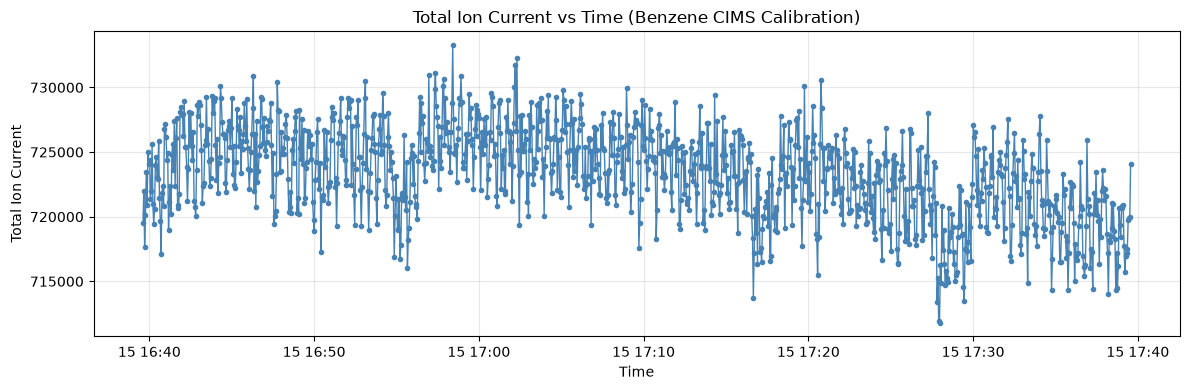

In [8]:

col = 'TotalIonCurrent'

# 创建 1 张图，尺寸 12x4 英寸
plt.figure(figsize=(12, 4))

# 画时间序列：X 为时间列，Y 为总离子流；'o-' 表示点+线，ms=3 点大小，lw=1 线宽
plt.plot(df_clean['tWvDateTime'], df_clean[col],
         'o-', ms=3, lw=1, color='steelblue')

# 设置 X 轴标签
plt.xlabel('Time')

# 设置 Y 轴标签
plt.ylabel('Total Ion Current')

# 设置标题
plt.title('Total Ion Current vs Time (Benzene CIMS Calibration)')

# 打开淡网格，alpha=0.3 透明度，不遮挡数据
plt.grid(alpha=0.3)

# 自动调整布局，避免标签被裁切
plt.tight_layout()

# 显示图形
plt.show()

In [10]:
x = df_clean['TotalIonCurrent'].values
n = len(x)

# 1. 描述统计
print("均值:", x.mean(), "标准差:", x.std(ddof=1),
      "最小:", x.min(), "最大:", x.max(), "CV:", x.std(ddof=1)/x.mean())

# 2. 正态检验
W, p = stats.shapiro(x)
print("Shapiro-Wilk p =", p)

# 3. 线性趋势检验
t = np.arange(n)
slope, _, r, p_slope, _ = stats.linregress(t, x)
print("斜率 =", slope, "R² =", r**2, "p =", p_slope)

# 4. 一阶自相关
rho1 = np.corrcoef(x[:-1], x[1:])[0, 1]
print("lag-1 自相关 =", rho1)

# 5. 前后时段均值差异
k = n // 3
tt, pt = stats.ttest_ind(x[:k], x[-k:], equal_var=False)
print("前1/3均值 =", x[:k].mean(), "后1/3均值 =", x[-k:].mean(), "p =", pt)

均值: 723321.3664166667 标准差: 3500.5131473291663 最小: 711807.5 最大: 733264.75 CV: 0.0048394991629663936
Shapiro-Wilk p = 2.435729263973812e-06
斜率 = -4.852824677100471 R² = 0.23081752716519688 p = 2.578618913533982e-70
lag-1 自相关 = 0.6721604335942575
前1/3均值 = 724744.7975999999 后1/3均值 = 720944.888525 p = 3.253805513095546e-56
